# 01 · Data audit: what the raw eCourts data really looks like

**TAREEKH**, IDSE course project. Source: Development Data Lab's judicial data (eCourts,
2010–2018), **ODbL v1.0**. This notebook shows the mess *before* any cleaning, and how much
each cleaning rule fixes. Every number is computed here; nothing is typed in.

Run `scripts/build_dataset.py` and `scripts/label_cases.py` first (see `pipeline/README.md`).

In [1]:
import sys, json, glob
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tareekh import plotstyle as ps
ps.apply()
CLEAN, KEYS, FIG = ROOT / "data/clean", ROOT / "data/raw/ddl/keys", ROOT / "reports/figures"
A = json.load(open(ROOT / "reports/analysis.json"))
pd.set_option("display.max_colwidth", 70)

## 1. One row per case, everything stored as text

Tamil Nadu, all filing years. Codes such as `"01"` must stay text, or they stop matching the lookup keys.

In [2]:
tn = pd.concat([pd.read_parquet(f) for f in sorted(glob.glob(str(CLEAN / "10/cases_*.parquet")))],
               ignore_index=True)
print(f"{len(tn):,} Tamil Nadu cases, {tn.shape[1]} columns")
tn.head(3)

3,640,055 Tamil Nadu cases, 19 columns


,ddl_case_id,year,state_code,dist_code,court_no,cino,judge_position,female_defendant,female_petitioner,female_adv_def,female_adv_pet,type_name,purpose_name,disp_name,date_of_filing,date_of_decision,date_first_list,date_last_list,date_next_list
0,10-01-02-230401000062010,2010,10,01,02,TNDP060000742010,judicial magistrate court,0 male,-9998 unclear,0,-9999,682,4577,4,2010-02-12,2018-03-14,2014-01-30,2018-03-14,2018-03-14
1,10-01-02-230401000092010,2010,10,01,02,TNDP060000832010,judicial magistrate court,0 male,-9998 unclear,0,-9999,682,509,4,2010-02-23,2017-05-25,2013-12-20,2017-05-25,2017-05-25
2,10-01-02-230401000102010,2010,10,01,02,TNDP060000792010,judicial magistrate court,1 female,-9998 unclear,0,-9999,682,3139,4,2010-02-23,2018-02-03,2013-12-19,2018-02-03,2018-02-03


## 2. Missing values: blanks and sentinel codes

Blank strings are missing values; so are DDL's sentinels `-9998` (unclear) and `-9999` (missing).

In [3]:
def missing(col):
    s = tn[col]
    return pd.Series({"blank": (s == "").mean(),
                      "sentinel -9998 (unclear)": s.str.startswith("-9998").mean(),
                      "sentinel -9999 (missing)": s.str.startswith("-9999").mean()})
miss = pd.DataFrame({c: missing(c) for c in tn.columns}).T
miss[(miss > 0).any(axis=1)].style.format("{:.1%}")

,blank,sentinel -9998 (unclear),sentinel -9999 (missing)
female_defendant,0.0%,21.6%,1.7%
female_petitioner,0.0%,44.9%,1.5%
female_adv_def,0.0%,2.8%,76.5%
female_adv_pet,0.0%,11.9%,29.8%
purpose_name,4.1%,0.0%,0.0%
date_of_decision,26.2%,0.0%,0.0%
date_first_list,3.6%,0.0%,0.0%
date_last_list,0.0%,0.0%,0.0%
date_next_list,3.5%,0.0%,0.0%


## 3. Impossible dates

Year 0001, `5000-01-01`, 9201-…: typos and placeholders. We blank anything outside 1950–2022 and count it, rather than guess the intended date.

In [4]:
from tareekh.cases import decode
lab = pd.read_parquet(CLEAN / "10/labelled.parquet")
dates = ["date_of_decision", "date_first_list", "date_last_list", "date_next_list"]
raw_years = {c: pd.to_numeric(tn[c].str[:4], errors="coerce") for c in dates}
bad = pd.DataFrame({c: {"outside 1950-2022": int(lab[f"{c}_impossible"].sum()),
                        "earliest year typed": int(raw_years[c].min()),
                        "latest year typed": int(raw_years[c].max())} for c in dates}).T
print(f"Decided before it was filed: {int(lab.decided_before_filing.sum()):,} cases")
bad

Decided before it was filed: 23,497 cases


,outside 1950-2022,earliest year typed,latest year typed
date_of_decision,66,1900,5000
date_first_list,67,2,3201
date_last_list,95219,1994,5000
date_next_list,2691,1994,5201


## 4. One law, hundreds of spellings

The law names are typed by court staff. Counts are case–law rows across all of India (`act_key.csv`).

In [5]:
from tareekh.acts import canonical_act, UNKNOWN
acts = pd.read_csv(KEYS / "act_key.csv", dtype=str, keep_default_na=False)
acts["count"] = pd.to_numeric(acts["count"])
acts["law"] = acts.act_s.map(canonical_act)
named = ~acts.law.isin([UNKNOWN, "Other"])
print(f"{len(acts):,} raw law names -> {acts.loc[named, 'law'].nunique()} named laws; "
      f"{acts.loc[named, 'count'].sum() / acts['count'].sum():.1%} of rows named, "
      f"{acts.loc[acts.law == UNKNOWN, 'count'].sum() / acts['count'].sum():.1%} junk ('.', '---', 'ACT'), "
      f"{acts.loc[acts.law == 'Other', 'count'].sum() / acts['count'].sum():.1%} left as Other")
acts[acts.law == "Negotiable Instruments Act"].nlargest(12, "count")[["act_s", "count"]]

29,857 raw law names -> 54 named laws; 94.1% of rows named, 2.0% junk ('.', '---', 'ACT'), 4.0% left as Other


,act_s,count
11007,Negotiable Instruments Act,1740873.0
10809,"NEGOTIABLE INSTRUMENTS ACT, 1881",790884.0
10808,NEGOTIABLE INSTRUMENTS ACT,780690.0
11001,Negotiable Instrument Act,358348.0
11009,Negotiable Instruments Act \,281877.0
11012,Negotiable Instruments Act 1881,240837.0
11023,NegotiableInstrumentsAct,104925.0
10734,N. I. Act,71406.0
11014,Negotiable Instruments Act \,63929.0
19894,U/S 138 of N.I Act,56916.0


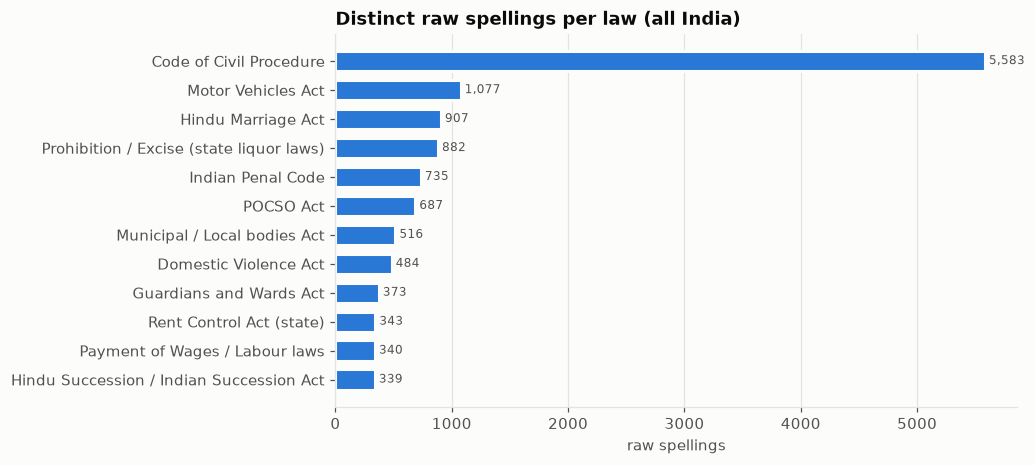

In [6]:
spellings = acts[named].groupby("law").size().nlargest(12)
fig, ax = plt.subplots(figsize=(8, 4.4))
ps.hbar(ax, list(spellings.index), list(spellings.values), fmt="{:,}")
ax.set_title("Distinct raw spellings per law (all India)")
ax.set_xlabel("raw spellings")
ps.save(fig, "audit_law_spellings", FIG)

## 5. Court names and section numbers

The court ("judge position") is free text too, and so is the section a case was filed under.

In [7]:
from tareekh.courts import court_level
levels = tn.judge_position.map(court_level)
print(f"{tn.judge_position.nunique()} raw court names -> {levels.nunique()} court levels")
print(tn.judge_position[tn.judge_position.str.contains("trail|musif|subardinate|mgistrate")].unique()[:6])
pd.DataFrame(A["tamil_nadu"]["cleaning"]["section_strings"]).T.rename(
    columns={"raw": "raw section strings", "after": "after primary_section()"})

116 raw court names -> 15 court levels


<ArrowStringArray>
[   'principal district musif court complex, thoothukud',
 'special court for the exclusive trail of ec act cases',
                    'district musif court, virudhunagar',
                             'judicial mgistrate, sulur',
                         'subardinate court jayankondam']
Length: 5, dtype: str


,raw section strings,after primary_section()
Indian Penal Code,493,492
Negotiable Instruments Act,2454,227
Motor Vehicles Act,24310,616
Code of Civil Procedure,61776,1134


## 6. Two outcome fields that disagree, and gender that is mostly unclear

In [8]:
lab["has_date"] = lab.date_of_decision.notna()
print(pd.crosstab(lab.disp.where(lab.disp.isin(["disposition var missing", "transferred", "dismissed",
                                                "convicted", "acquitted"]), "other"),
                  lab.has_date, margins=True))
g = A["tamil_nadu"]["cleaning"]["gender_unclear"]
print(f"\nGender 'unclear': defendant {g['defendant']:.0%}, petitioner {g['petitioner']:.0%}. "
      "Gender is used for description only, never as a model input.")

has_date                  False     True      All
disp                                             
acquitted                     1   232171   232172
convicted                     3   417100   417103
dismissed                    63   630870   630933
disposition var missing  952858     7912   960770
other                        63  1149049  1149112
transferred                   5   249960   249965
All                      952993  2687062  3640055

Gender 'unclear': defendant 22%, petitioner 45%. Gender is used for description only, never as a model input.


## Takeaways

- The raw data is genuinely messy: tens of thousands of law spellings, impossible dates,
  sentinel codes, two outcome fields that disagree, free-text courts and sections.
- Each cleaning rule is explicit, tested (`pipeline/tests/`) and measured: we report how many
  rows it touched instead of silently fixing them.
- Nothing ambiguous is guessed: impossible dates are blanked and counted, unmatched laws stay
  "Other", unreadable court codes stay "unclear".